# Healthcare & Lifestyle Analytics — BRFSS 2023

## End-to-end project: EDA, visualizations, classification, regression, and prediction

**Dataset:** CDC Behavioral Risk Factor Surveillance System (BRFSS), 2023 annual survey.

The CDC reports **433,323 records and 345 variables** for the 2023 combined landline/cell-phone data file. The data covers health status, physical activity, chronic conditions, demographics, tobacco use, alcohol consumption, and other health behaviors. See the [official CDC data page](https://www.cdc.gov/brfss/annual_data/annual_2023.html).

### Project tasks
1. Download and load the official CDC data.
2. Inspect data quality and select interpretable health/lifestyle variables.
3. Perform EDA and create visualizations.
4. Classification: predict diabetes status from selected lifestyle and health indicators.
5. Regression: predict reported sleep hours from selected lifestyle and demographic indicators.
6. Compare models, inspect errors and feature importance, and make example predictions.

**Important:** BRFSS is a complex survey, not a clinical dataset. The models are for education and exploratory analysis, not diagnosis. Results from an ordinary train/test split are not population estimates; formal public-health estimates should account for survey weights and design.

## 1. Install and import libraries

In [ ]:
!pip -q install pyreadstat seaborn scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 34.0 MB/s eta 0:00:00


In [ ]:
import os
import zipfile
import requests
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
print("Setup complete.")

Setup complete.


## 2. Download the official CDC dataset

The compressed SAS Transport file is about 64 MB. This cell downloads it directly from the CDC and extracts the `.XPT` file. If you prefer, you can manually download the file from the [CDC 2023 BRFSS page](https://www.cdc.gov/brfss/annual_data/annual_2023.html).

In [ ]:
import zipfile
import os
import pandas as pd

zip_path = "/content/LLCP2023XPT.zip"
extract_dir = "/content/brfss_2023"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    actual_name = next((name for name in z.namelist() if name.strip().upper() == "LLCP2023.XPT"), None)
    if actual_name is None:
        raise KeyError("Could not find LLCP2023.XPT in the archive.")

    z.extract(actual_name, extract_dir)

    extracted_path = os.path.join(extract_dir, actual_name)
    target_path = os.path.join(extract_dir, "LLCP2023.XPT")
    if extracted_path != target_path:
        os.rename(extracted_path, target_path)

xpt_path = os.path.join(extract_dir, "LLCP2023.XPT")
df_raw = pd.read_sas(xpt_path, format="xport", encoding="utf-8")

df_raw.columns = df_raw.columns.str.upper().str.strip()

print("Dataset loaded successfully!")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())

Dataset loaded successfully!
Rows: 433323
Columns: 350


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,NUMADULT,RESPSLC1,LANDSEX2,LNDSXBRT,SAFETIME,CTELNUM1,CELLFON5,CADULT1,CELLSEX2,CELSXBRT,PVTRESD3,CCLGHOUS,CSTATE1,LANDLINE,HHADULT,SEXVAR,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,PRIMINS1,PERSDOC3,MEDCOST1,CHECKUP1,EXERANY2,EXRACT12,EXEROFT1,EXERHMM1,EXRACT22,EXEROFT2,EXERHMM2,STRENGTH,BPHIGH6,BPMEDS1,CHOLCHK3,...,_PACAT3,_PAINDX3,_PA150R4,_PA300R4,_PA30023,_PASTRNG,_PAREC3,_PASTAE3,_RFHYPE6,_CHOLCH3,_RFCHOL3,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR2,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACEPRV,_SEX,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG1,_SMOKER3,_RFSMOK3,_CURECI2,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,1.0,NaN,1.0,2.0,1.0,2.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0,88.0,88.0,NaN,3.0,1.0,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,888.0,1.0,1.0,3.0,...,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,13.0,2.0,80.0,6.0,63.0,160.0,7802.0,3047.0,4.0,2.0,1.0,3.0,9.0,4.0,1.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0,88.0,88.0,NaN,3.0,1.0,2.0,2.0,1.0,1.0,106.0,30.0,88.0,NaN,NaN,888.0,1.0,2.0,2.0,...,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,13.0,2.0,80.0,6.0,57.0,145.0,5987.0,2856.0,3.0,2.0,1.0,3.0,9.0,4.0,1.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0,6.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,205.0,15.0,88.0,NaN,NaN,205.0,1.0,1.0,2.0,...,9.0,9.0,9.0,9.0,9.0,2.0,9.0,9.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,13.0,2.0,80.0,6.0,64.0,163.0,5897.0,2231.0,2.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,1.0,NaN,1.0,2.0,1.0,2.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,2.0,2.0,88.0,88.0,3.0,1.0,2.0,3.0,1.0,1.0,103.0,30.0,88.0,NaN,NaN,888.0,3.0,NaN,3.0,...,9.0,1.0,1.0,9.0,9.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,12.0,2.0,78.0,6.0,66.0,168.0,7711.0,2744.0,3.0,2.0,1.0,3.0,9.0,4.0,1.0,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0,88.0,88.0,NaN,3.0,1.0,2.0,1.0,1.0,1.0,102.0,45.0,8.0,107.0,100.0,888.0,1.0,1.0,2.0,...,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,12.0,2.0,76.0,6.0,68.0,173.0,7711.0,2585.0,3.0,2.0,1.0,3.0,5.0,4.0,1.0,1.0,1.0,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


## 3. Understand the raw data

In [ ]:
print("Shape:", df_raw.shape)
print("\nFirst 60 columns:")
print(df_raw.columns[:60].tolist())

print("\nData types:")
display(df_raw.dtypes.astype(str).value_counts().to_frame("Number of columns"))

print("\nMissingness among the first 30 columns:")
missing_overview = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing Percent": (df_raw.isna().mean() * 100).round(2)
}).sort_values("Missing Percent", ascending=False)
display(missing_overview.head(30))

print("\nDuplicate rows:", df_raw.duplicated().sum())

Shape: (433323, 350)

First 60 columns:
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX2', 'LNDSXBRT', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX2', 'CELSXBRT', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS1', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'EXRACT12', 'EXEROFT1', 'EXERHMM1', 'EXRACT22', 'EXEROFT2', 'EXERHMM2', 'STRENGTH', 'BPHIGH6', 'BPMEDS1', 'CHOLCHK3', 'TOLDHI3', 'CHOLMED3', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNC1', 'CHCOCNC1', 'CHCCOPD3']

Data types:


,Number of columns
float64,345
object,5



Missingness among the first 30 columns:


,Missing Count,Missing Percent
INDORTAN,433323,100.00
COLGHOUS,433311,100.00
NUMBURN3,433323,100.00
SUNPRTCT,433323,100.00
WKDAYOUT,433323,100.00
WKENDOUT,433323,100.00
LASTSIG4,433177,99.97
LNDSXBRT,433154,99.96
CSRVCTL2,433101,99.95
VCLNTES2,432983,99.92



Duplicate rows: 0


## 4. Select useful health and lifestyle variables

BRFSS uses numeric response codes. We select variables commonly used in the 2023 public-use file, then check which columns are actually present before proceeding.

| Variable | Meaning |
|---|---|
| `_DIABETE4` | Diabetes status |
| `_BMI5` | Calculated BMI × 100 |
| `_BMI5CAT` | BMI category |
| `_TOTINDA` | Leisure-time physical activity indicator |
| `_SMOKER3` | Smoking status category |
| `SLEPTIM1` | Hours of sleep in a 24-hour period |
| `GENHLTH` | General health rating |
| `PHYSHLTH` | Days physical health was not good in past 30 days |
| `MENTHLTH` | Days mental health was not good in past 30 days |
| `_AGEG5YR` | Age group |
| `SEXVAR` | Sex variable |
| `_RFHYPE6` | High blood pressure indicator |
| `_CHOLCH3` | Cholesterol check indicator |
| `_MICHD` | History of coronary heart disease or heart attack |
| `_RACE` | Race/ethnicity calculated variable |
| `_EDUCAG` | Education category |
| `_INCOMG1` | Income category |

Exact availability and coding can vary across releases. We print the columns available in the downloaded file before creating the analysis table.

In [ ]:
rest_matches = [c for c in df_raw.columns if "REST" in c or "HOUR" in c or "DUR" in c]
print("Potential sleep/rest column matches:", rest_matches)

sleep_exact = [c for c in df_raw.columns if c.upper().strip() == "SLEPTIM1"]
print("Exact SLEPTIM1 match in columns?", sleep_exact)

candidate_vars = [
    "DIABETE4", "_BMI5", "_BMI5CAT", "_TOTINDA", "_SMOKER3", "SLEPTIM1",
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "_AGEG5YR", "SEXVAR",
    "_RFHYPE6", "_CHOLCH3", "_MICHD", "_RACE", "_EDUCAG", "_INCOMG1",
    "_STATE", "_LLCPWT", "_STSTR", "_PSU"
]

available_vars = [c for c in candidate_vars if c in df_raw.columns]
missing_vars = [c for c in candidate_vars if c not in df_raw.columns]

print("\nAvailable selected variables:", available_vars)
print("Not present in this file:", missing_vars)

df = df_raw[available_vars].copy()
display(df.head())

Potential sleep/rest column matches: ['PADUR1_', 'PADUR2_']
Exact SLEPTIM1 match in columns? []

Available selected variables: ['DIABETE4', '_BMI5', '_BMI5CAT', '_TOTINDA', '_SMOKER3', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', '_AGEG5YR', 'SEXVAR', '_RFHYPE6', '_CHOLCH3', '_MICHD', '_RACE', '_EDUCAG', '_INCOMG1', '_STATE', '_LLCPWT', '_STSTR', '_PSU']
Not present in this file: ['SLEPTIM1']


,DIABETE4,_BMI5,_BMI5CAT,_TOTINDA,_SMOKER3,GENHLTH,PHYSHLTH,MENTHLTH,_AGEG5YR,SEXVAR,_RFHYPE6,_CHOLCH3,_MICHD,_RACE,_EDUCAG,_INCOMG1,_STATE,_LLCPWT,_STSTR,_PSU
0,1.0,3047.0,4.0,2.0,4.0,2.0,88.0,88.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,9.0,1.0,605.427887,11011.0,2.023000e+09
1,3.0,2856.0,3.0,1.0,4.0,2.0,88.0,88.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,9.0,1.0,1121.992705,11012.0,2.023000e+09
2,3.0,2231.0,2.0,1.0,3.0,4.0,6.0,2.0,13.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,600.963308,11011.0,2.023000e+09
3,3.0,2744.0,3.0,1.0,4.0,2.0,2.0,88.0,12.0,2.0,1.0,1.0,2.0,1.0,3.0,9.0,1.0,605.427887,11011.0,2.023000e+09
4,1.0,2585.0,3.0,1.0,4.0,4.0,88.0,88.0,12.0,2.0,2.0,1.0,2.0,1.0,3.0,5.0,1.0,281.711042,11011.0,2.023000e+09


## 5. Clean response codes and create readable labels

Many BRFSS fields use special codes such as `7`, `9`, `77`, `99`, or `999` for refused, don't know, or not asked. These codes must not be treated as real measurements. The cleaning below uses documented common codes for selected variables and leaves uncertain/unrecognized codes as missing where appropriate. Check the CDC codebook for your exact release before interpreting results.

In [ ]:
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

clean = df.copy()

if "DIABETE4" not in clean.columns:
    raise ValueError("The DIABETE4 diabetes variable is unavailable in this file.")
clean["DIABETES_BINARY"] = clean["DIABETE4"].map({1: 1, 3: 0})

if "_BMI5" in clean.columns:
    clean["BMI"] = clean["_BMI5"].where(clean["_BMI5"] > 0) / 100.0

if "SLEPTIM1" in clean.columns:
    clean["SLEEP_HOURS"] = clean["SLEPTIM1"].where(clean["SLEPTIM1"].between(1, 24))
if "PHYSHLTH" in clean.columns:
    clean["PHYSICAL_UNHEALTHY_DAYS"] = clean["PHYSHLTH"].replace({88: 0, 77: np.nan, 99: np.nan})
    clean.loc[~clean["PHYSICAL_UNHEALTHY_DAYS"].between(0, 30), "PHYSICAL_UNHEALTHY_DAYS"] = np.nan
if "MENTHLTH" in clean.columns:
    clean["MENTAL_UNHEALTHY_DAYS"] = clean["MENTHLTH"].replace({88: 0, 77: np.nan, 99: np.nan})
    clean.loc[~clean["MENTAL_UNHEALTHY_DAYS"].between(0, 30), "MENTAL_UNHEALTHY_DAYS"] = np.nan

label_maps = {
    "GENHLTH": {1:"Excellent", 2:"Very good", 3:"Good", 4:"Fair", 5:"Poor"},
    "_TOTINDA": {1:"Active", 2:"Inactive"},
    "_SMOKER3": {1:"Every day", 2:"Some days", 3:"Former smoker", 4:"Never smoked"},
    "_BMI5CAT": {1:"Underweight", 2:"Normal weight", 3:"Overweight", 4:"Obese"},
    "SEXVAR": {1:"Male", 2:"Female"},
    "_RFHYPE6": {1:"No high blood pressure", 2:"High blood pressure"},
    "_CHOLCH3": {1:"Cholesterol checked", 2:"Not checked"},
    "_MICHD": {1:"Heart disease/heart attack history", 2:"No history"},
    "_AGEG5YR": {i: label for i, label in enumerate([
        "Age 18–24", "Age 25–29", "Age 30–34", "Age 35–39", "Age 40–44",
        "Age 45–49", "Age 50–54", "Age 55–59", "Age 60–64", "Age 65–69",
        "Age 70–74", "Age 75–79", "Age 80+"
    ], start=1)},
    "_EDUCAG": {1:"Did not graduate high school", 2:"High school graduate", 3:"Some college/technical school", 4:"College graduate"},
    "_INCOMG1": {1:"Under $15k", 2:"$15k–<$25k", 3:"$25k–<$35k", 4:"$35k–<$50k", 5:"$50k–<$100k", 6:"$100k–<$200k", 7:"$200k+"}
}
for col, mapping in label_maps.items():
    if col in clean.columns:
        clean[col + "_LABEL"] = clean[col].map(mapping)

display(clean.head())

,DIABETE4,_BMI5,_BMI5CAT,_TOTINDA,_SMOKER3,GENHLTH,PHYSHLTH,MENTHLTH,_AGEG5YR,SEXVAR,_RFHYPE6,_CHOLCH3,_MICHD,_RACE,_EDUCAG,_INCOMG1,_STATE,_LLCPWT,_STSTR,_PSU,DIABETES_BINARY,BMI,PHYSICAL_UNHEALTHY_DAYS,MENTAL_UNHEALTHY_DAYS,GENHLTH_LABEL,_TOTINDA_LABEL,_SMOKER3_LABEL,_BMI5CAT_LABEL,SEXVAR_LABEL,_RFHYPE6_LABEL,_CHOLCH3_LABEL,_MICHD_LABEL,_AGEG5YR_LABEL,_EDUCAG_LABEL,_INCOMG1_LABEL
0,1.0,3047.0,4.0,2.0,4.0,2.0,88.0,88.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,9.0,1.0,605.427887,11011.0,2.023000e+09,1.0,30.47,0.0,0.0,Very good,Inactive,Never smoked,Obese,Female,High blood pressure,Cholesterol checked,No history,Age 80+,Some college/technical school,NaN
1,3.0,2856.0,3.0,1.0,4.0,2.0,88.0,88.0,13.0,2.0,2.0,1.0,2.0,1.0,3.0,9.0,1.0,1121.992705,11012.0,2.023000e+09,0.0,28.56,0.0,0.0,Very good,Active,Never smoked,Overweight,Female,High blood pressure,Cholesterol checked,No history,Age 80+,Some college/technical school,NaN
2,3.0,2231.0,2.0,1.0,3.0,4.0,6.0,2.0,13.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,600.963308,11011.0,2.023000e+09,0.0,22.31,6.0,2.0,Fair,Active,Former smoker,Normal weight,Female,High blood pressure,Cholesterol checked,No history,Age 80+,High school graduate,Under $15k
3,3.0,2744.0,3.0,1.0,4.0,2.0,2.0,88.0,12.0,2.0,1.0,1.0,2.0,1.0,3.0,9.0,1.0,605.427887,11011.0,2.023000e+09,0.0,27.44,2.0,0.0,Very good,Active,Never smoked,Overweight,Female,No high blood pressure,Cholesterol checked,No history,Age 75–79,Some college/technical school,NaN
4,1.0,2585.0,3.0,1.0,4.0,4.0,88.0,88.0,12.0,2.0,2.0,1.0,2.0,1.0,3.0,5.0,1.0,281.711042,11011.0,2.023000e+09,1.0,25.85,0.0,0.0,Fair,Active,Never smoked,Overweight,Female,High blood pressure,Cholesterol checked,No history,Age 75–79,Some college/technical school,$50k–<$100k


## 6. EDA — missing values and target distribution

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DIABETES_BINARY,418492.0,NaN,NaN,NaN,0.142861,0.349931,0.0,0.0,0.0,0.0,1.0
BMI,392788.0,NaN,NaN,NaN,28.479288,6.541975,12.02,24.1,27.4,31.62,99.84
PHYSICAL_UNHEALTHY_DAYS,422538.0,NaN,NaN,NaN,4.482591,8.827409,0.0,0.0,0.0,4.0,30.0
MENTAL_UNHEALTHY_DAYS,425215.0,NaN,NaN,NaN,4.358383,8.320868,0.0,0.0,0.0,5.0,30.0
GENHLTH_LABEL,432061,5,Good,144209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_TOTINDA_LABEL,432072,2,Active,325227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_SMOKER3_LABEL,410261,4,Never smoked,251981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_AGEG5YR_LABEL,425544,13,Age 65–69,46099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEXVAR_LABEL,433323,2,Female,229541,NaN,NaN,NaN,NaN,NaN,NaN,NaN


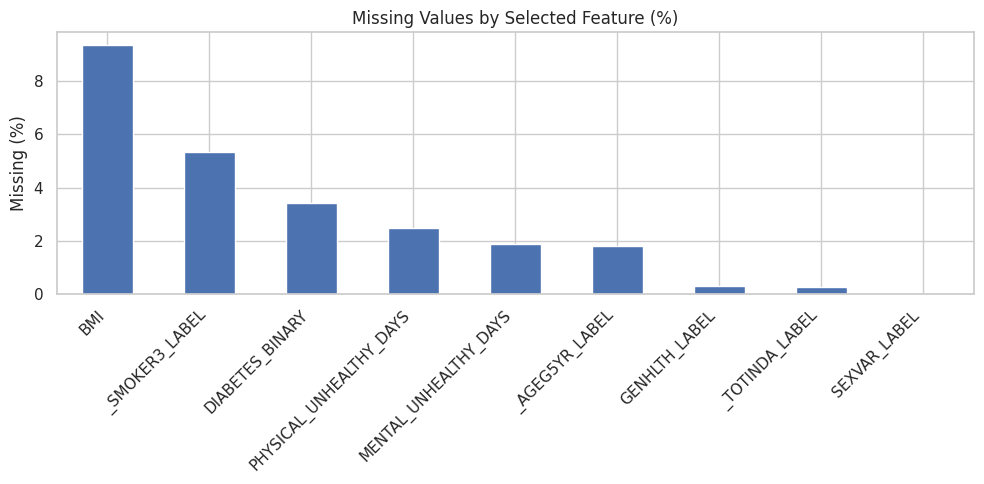

,Respondents
DIABETES_BINARY,
No diagnosed diabetes,358706
Diagnosed diabetes,59786


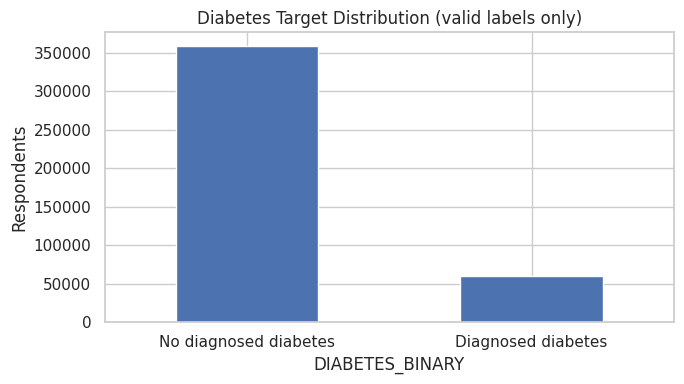

In [ ]:
eda_cols = [c for c in [
    "DIABETES_BINARY", "BMI", "SLEEP_HOURS", "PHYSICAL_UNHEALTHY_DAYS",
    "MENTAL_UNHEALTHY_DAYS", "GENHLTH_LABEL", "_TOTINDA_LABEL",
    "_SMOKER3_LABEL", "_AGEG5YR_LABEL", "SEXVAR_LABEL"
] if c in clean.columns]

eda_df = clean[eda_cols].copy()
display(eda_df.describe(include="all").T)

miss = (eda_df.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
miss.plot(kind="bar")
plt.title("Missing Values by Selected Feature (%)")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

if "DIABETES_BINARY" in clean.columns:
    target_counts = clean["DIABETES_BINARY"].map({0:"No diagnosed diabetes", 1:"Diagnosed diabetes"}).value_counts()
    display(target_counts.to_frame("Respondents"))
    target_counts.plot(kind="bar", figsize=(7, 4))
    plt.title("Diabetes Target Distribution (valid labels only)")
    plt.ylabel("Respondents")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 7. EDA — numeric distributions

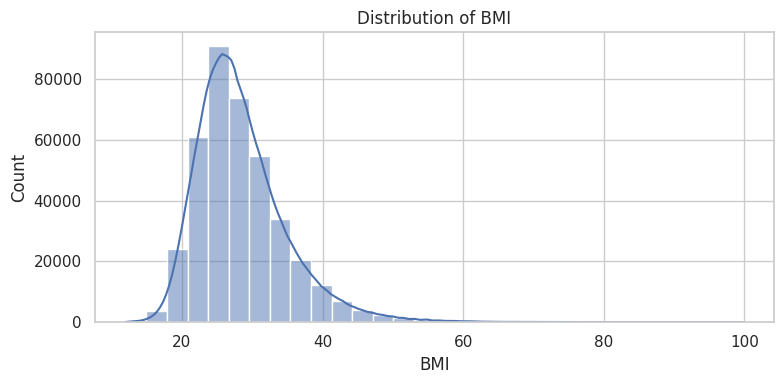

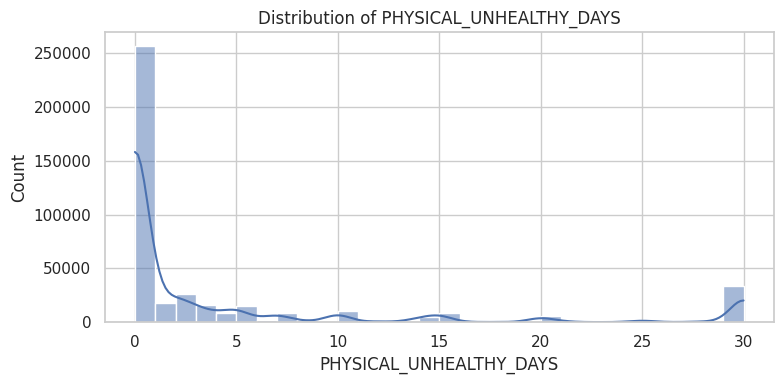

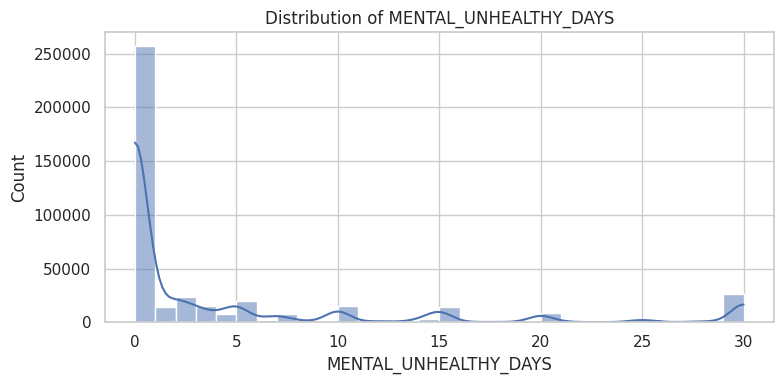

In [ ]:
numeric_plot_cols = [c for c in ["BMI", "SLEEP_HOURS", "PHYSICAL_UNHEALTHY_DAYS", "MENTAL_UNHEALTHY_DAYS"] if c in clean.columns]
for col in numeric_plot_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(clean[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

## 8. EDA — lifestyle and health visualizations

,Diagnosed diabetes (%)
_TOTINDA_LABEL,
Active,11.32
Inactive,23.33


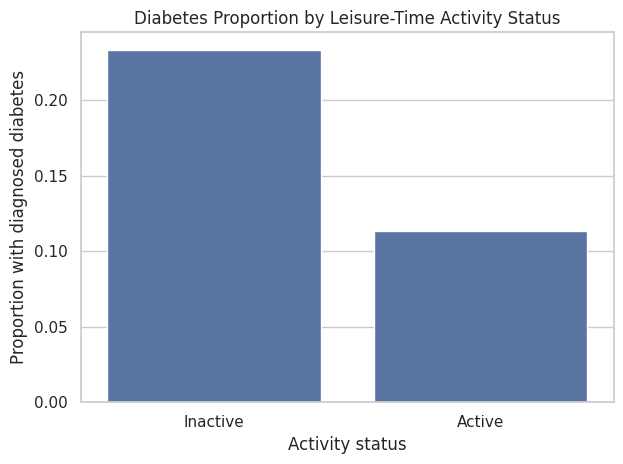

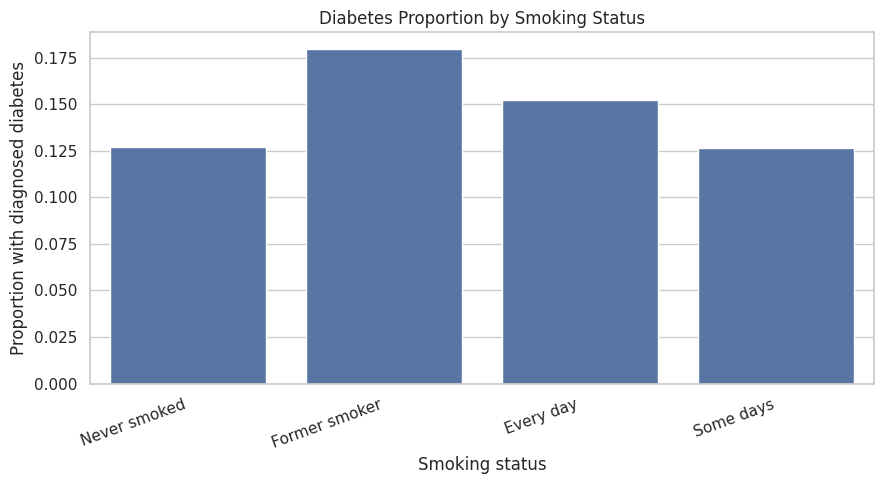

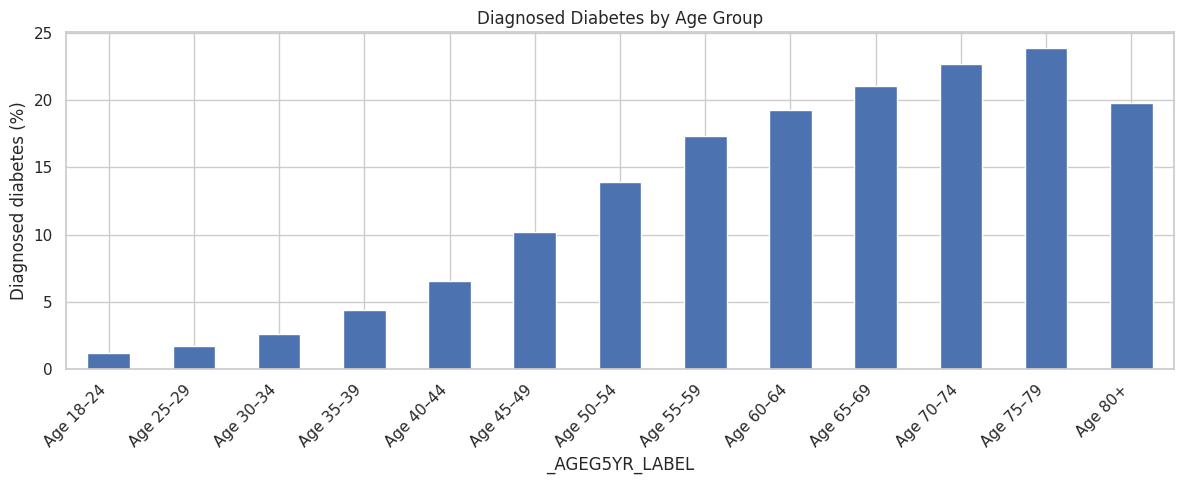

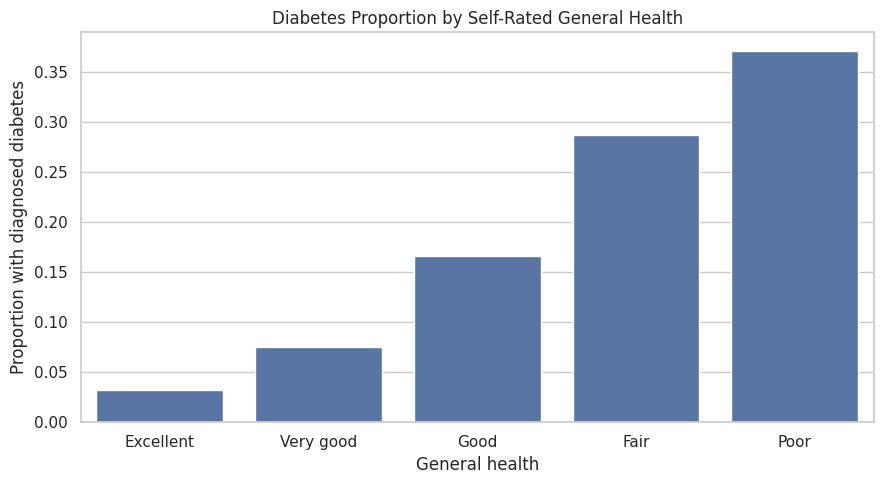

In [ ]:
if {"_TOTINDA_LABEL", "DIABETES_BINARY"}.issubset(clean.columns):
    temp = clean.dropna(subset=["_TOTINDA_LABEL", "DIABETES_BINARY"]).copy()
    temp["Diabetes status"] = temp["DIABETES_BINARY"].map({0:"No diagnosed diabetes", 1:"Diagnosed diabetes"})
    rate = temp.groupby("_TOTINDA_LABEL")["DIABETES_BINARY"].mean() * 100
    display(rate.rename("Diagnosed diabetes (%)").to_frame().round(2))
    sns.barplot(data=temp, x="_TOTINDA_LABEL", y="DIABETES_BINARY", errorbar=None)
    plt.title("Diabetes Proportion by Leisure-Time Activity Status")
    plt.ylabel("Proportion with diagnosed diabetes")
    plt.xlabel("Activity status")
    plt.tight_layout()
    plt.show()

if {"_SMOKER3_LABEL", "DIABETES_BINARY"}.issubset(clean.columns):
    temp = clean.dropna(subset=["_SMOKER3_LABEL", "DIABETES_BINARY"])
    plt.figure(figsize=(9, 5))
    sns.barplot(data=temp, x="_SMOKER3_LABEL", y="DIABETES_BINARY", errorbar=None)
    plt.title("Diabetes Proportion by Smoking Status")
    plt.ylabel("Proportion with diagnosed diabetes")
    plt.xlabel("Smoking status")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

if {"_AGEG5YR_LABEL", "DIABETES_BINARY"}.issubset(clean.columns):
    age_rate = clean.dropna(subset=["_AGEG5YR_LABEL", "DIABETES_BINARY"]).groupby("_AGEG5YR_LABEL")["DIABETES_BINARY"].mean() * 100
    age_rate.plot(kind="bar", figsize=(12, 5))
    plt.title("Diagnosed Diabetes by Age Group")
    plt.ylabel("Diagnosed diabetes (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

if {"GENHLTH_LABEL", "DIABETES_BINARY"}.issubset(clean.columns):
    plt.figure(figsize=(9, 5))
    sns.barplot(data=clean.dropna(subset=["GENHLTH_LABEL", "DIABETES_BINARY"]),
                x="GENHLTH_LABEL", y="DIABETES_BINARY", errorbar=None,
                order=["Excellent", "Very good", "Good", "Fair", "Poor"])
    plt.title("Diabetes Proportion by Self-Rated General Health")
    plt.ylabel("Proportion with diagnosed diabetes")
    plt.xlabel("General health")
    plt.tight_layout()
    plt.show()

## 9. Correlation and subgroup analysis

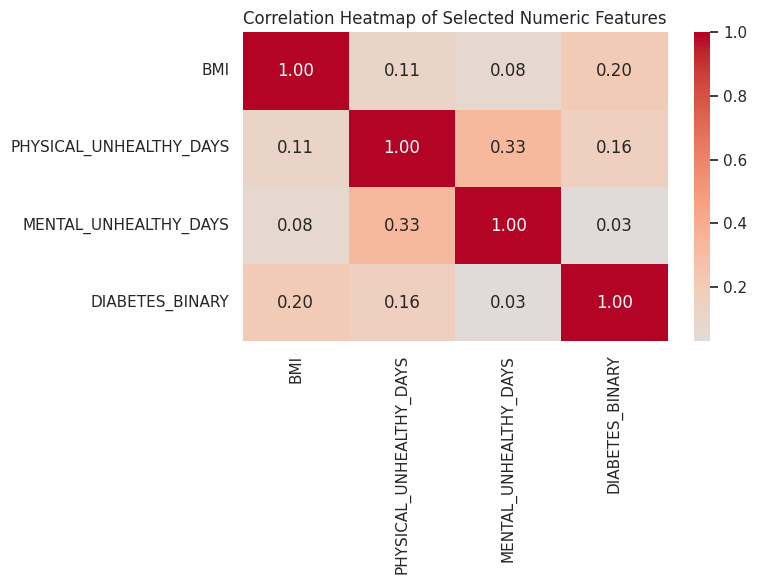

,mean,count,percent_diabetes
_BMI5CAT_LABEL,,,
Obese,0.23,123674,23.31
Overweight,0.13,135438,12.85
Normal weight,0.07,113853,6.99
Underweight,0.05,6617,5.41


In [ ]:
corr_cols = [c for c in ["BMI", "SLEEP_HOURS", "PHYSICAL_UNHEALTHY_DAYS", "MENTAL_UNHEALTHY_DAYS", "DIABETES_BINARY"] if c in clean.columns]
if len(corr_cols) >= 2:
    plt.figure(figsize=(8, 6))
    sns.heatmap(clean[corr_cols].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Correlation Heatmap of Selected Numeric Features")
    plt.tight_layout()
    plt.show()

if {"_BMI5CAT_LABEL", "DIABETES_BINARY"}.issubset(clean.columns):
    bmi_diabetes = clean.dropna(subset=["_BMI5CAT_LABEL", "DIABETES_BINARY"]).groupby("_BMI5CAT_LABEL")["DIABETES_BINARY"].agg(["mean", "count"])
    bmi_diabetes["percent_diabetes"] = bmi_diabetes["mean"] * 100
    display(bmi_diabetes.sort_values("percent_diabetes", ascending=False).round(2))

## 10. Classification — predict diagnosed diabetes

We use a balanced sample of up to 120,000 valid rows to keep model training manageable in free Colab. The features are selected health/lifestyle indicators. The model is a learning exercise and must not be used for medical decisions.

We exclude variables that directly encode the diabetes outcome. BMI, smoking, activity, sleep, age group, sex, general health, and unhealthy-day counts are included when available. The class labels are restricted to `1 = yes` and `3 = no`; prediabetes, pregnancy-only diabetes, refused, and unknown responses are not used as target labels.

In [ ]:
feature_candidates = [
    "BMI", "SLEEP_HOURS", "PHYSICAL_UNHEALTHY_DAYS", "MENTAL_UNHEALTHY_DAYS",
    "GENHLTH_LABEL", "_TOTINDA_LABEL", "_SMOKER3_LABEL", "_AGEG5YR_LABEL",
    "SEXVAR_LABEL", "_RFHYPE6_LABEL", "_CHOLCH3_LABEL", "_MICHD_LABEL",
    "_EDUCAG_LABEL", "_INCOMG1_LABEL", "_RACE"
]
cls_features = [c for c in feature_candidates if c in clean.columns]
cls_data = clean.dropna(subset=["DIABETES_BINARY"]).copy()

MAX_CLASS_ROWS = 120_000
if len(cls_data) > MAX_CLASS_ROWS:
    cls_data = cls_data.sample(MAX_CLASS_ROWS, random_state=RANDOM_STATE)

X = cls_data[cls_features].copy()
y = cls_data["DIABETES_BINARY"].astype(int)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Rows used:", len(cls_data))
print("Features:", cls_features)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Target proportions:")
display(y.value_counts(normalize=True).rename({0:"No diabetes",1:"Diabetes"}).to_frame("Proportion"))

Rows used: 120000
Features: ['BMI', 'PHYSICAL_UNHEALTHY_DAYS', 'MENTAL_UNHEALTHY_DAYS', 'GENHLTH_LABEL', '_TOTINDA_LABEL', '_SMOKER3_LABEL', '_AGEG5YR_LABEL', 'SEXVAR_LABEL', '_RFHYPE6_LABEL', '_CHOLCH3_LABEL', '_MICHD_LABEL', '_EDUCAG_LABEL', '_INCOMG1_LABEL', '_RACE']
Train shape: (96000, 14) Test shape: (24000, 14)
Target proportions:


,Proportion
DIABETES_BINARY,
No diabetes,0.854725
Diabetes,0.145275


In [ ]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", n_jobs=None),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=160, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=160, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
}

classifier_pipelines = {}
cls_results = []

for name, estimator in classifiers.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    classifier_pipelines[name] = pipe
    cls_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

cls_results_df = pd.DataFrame(cls_results).sort_values("F1", ascending=False)
display(cls_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1
2,Random Forest,0.7467,0.3286,0.7126,0.4498
0,Logistic Regression,0.7123,0.3072,0.7809,0.4409
3,Extra Trees,0.7145,0.3053,0.7565,0.4350
1,Decision Tree,0.6667,0.2776,0.8076,0.4132


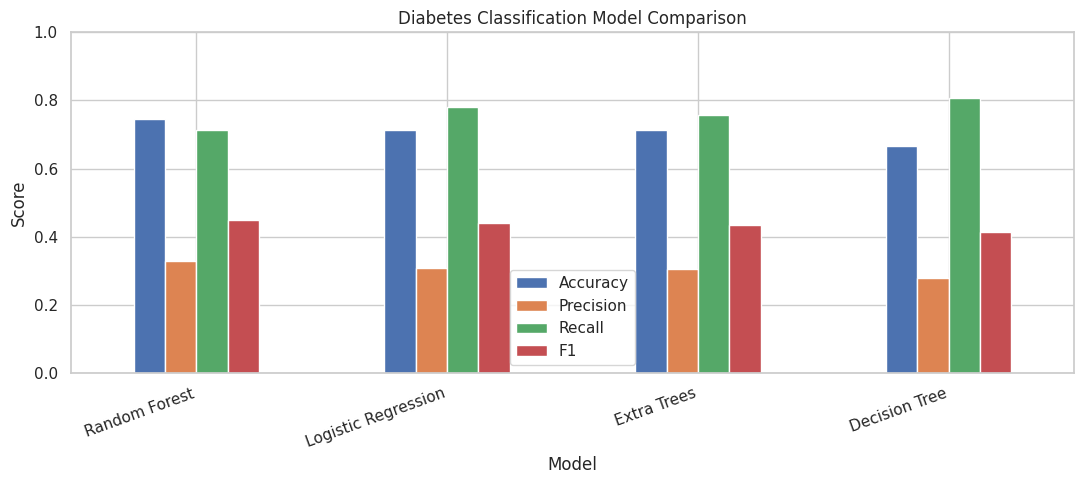

Best model by F1: Random Forest
                       precision    recall  f1-score   support

No diagnosed diabetes       0.94      0.75      0.84     20513
   Diagnosed diabetes       0.33      0.71      0.45      3487

             accuracy                           0.75     24000
            macro avg       0.63      0.73      0.64     24000
         weighted avg       0.85      0.75      0.78     24000



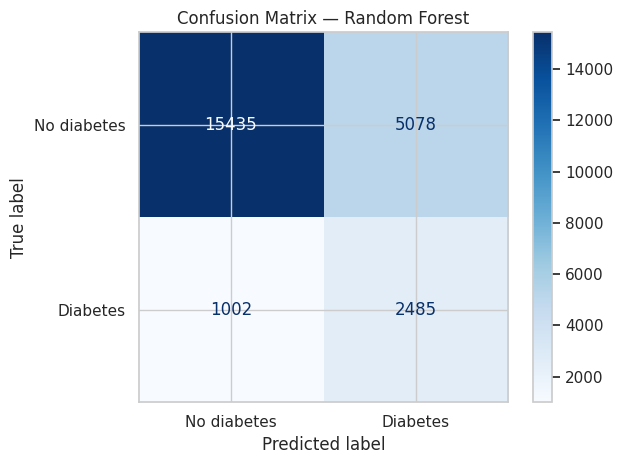

In [ ]:
cls_results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 5))
plt.title("Diabetes Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_cls_name = cls_results_df.iloc[0]["Model"]
best_cls_model = classifier_pipelines[best_cls_name]
best_cls_pred = best_cls_model.predict(X_test)

print("Best model by F1:", best_cls_name)
print(classification_report(y_test, best_cls_pred, target_names=["No diagnosed diabetes", "Diagnosed diabetes"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_cls_pred, display_labels=["No diabetes", "Diabetes"], cmap="Blues")
plt.title(f"Confusion Matrix — {best_cls_name}")
plt.tight_layout()
plt.show()

## 11. Regression — predict sleep duration

The regression task predicts reported hours of sleep (`SLEPTIM1`) from selected demographic, lifestyle, and health features. We exclude rows with invalid or missing sleep hours and do not include sleep duration itself as a predictor.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fallback regression target if SLEEP_HOURS is missing
target_col = "SLEEP_HOURS"
if "SLEEP_HOURS" not in clean.columns:
    print("SLEEP_HOURS is not available. Using PHYSICAL_UNHEALTHY_DAYS as the alternative target for regression demonstration.")
    target_col = "PHYSICAL_UNHEALTHY_DAYS"

reg_features_candidates = [
    "BMI", "MENTAL_UNHEALTHY_DAYS",
    "GENHLTH_LABEL", "_TOTINDA_LABEL", "_SMOKER3_LABEL", "_AGEG5YR_LABEL",
    "SEXVAR_LABEL", "_RFHYPE6_LABEL", "_CHOLCH3_LABEL", "_MICHD_LABEL",
    "_EDUCAG_LABEL", "_INCOMG1_LABEL", "_RACE"
]
# Ensure target column is excluded from predictors
reg_features = [c for c in reg_features_candidates if c in clean.columns and c != target_col]

reg_data = clean.dropna(subset=[target_col]).copy()
# Reduced sample size from 100k to 30k for fast execution
MAX_REG_ROWS = 30_000
if len(reg_data) > MAX_REG_ROWS:
    reg_data = reg_data.sample(MAX_REG_ROWS, random_state=RANDOM_STATE)

Xr = reg_data[reg_features].copy()
yr = reg_data[target_col].astype(float)
num_r = Xr.select_dtypes(include=np.number).columns.tolist()
cat_r = [c for c in Xr.columns if c not in num_r]

preprocessor_r = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_r),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_r)
])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE
)

# Slightly reduced n_estimators for much faster training
regressors = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=60, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees Regressor": ExtraTreesRegressor(n_estimators=60, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE)
}

reg_pipelines = {}
reg_results = []
for name, estimator in regressors.items():
    pipe = Pipeline([("preprocessor", preprocessor_r), ("model", estimator)])
    pipe.fit(Xr_train, yr_train)
    pred = pipe.predict(Xr_test)
    reg_pipelines[name] = pipe
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred)
    })

reg_results_df = pd.DataFrame(reg_results).sort_values("RMSE")
display(reg_results_df.round(4))

SLEEP_HOURS is not available. Using PHYSICAL_UNHEALTHY_DAYS as the alternative target for regression demonstration.


,Model,MAE,RMSE,R2
0,Ridge Regression,4.1568,6.7020,0.4144
2,Random Forest Regressor,4.1185,6.7181,0.4115
3,Extra Trees Regressor,4.1298,6.7861,0.3996
1,Decision Tree Regressor,4.1792,6.8251,0.3926


In [ ]:
reg_results_df.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(10, 5))
plt.title("Sleep Duration Regression — Error Comparison (lower is better)")
plt.ylabel("Hours")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_reg_name = reg_results_df.iloc[0]["Model"]
best_reg_model = reg_pipelines[best_reg_name]
best_reg_pred = best_reg_model.predict(Xr_test)

plt.figure(figsize=(6, 6))
sns.scatterplot(x=yr_test, y=best_reg_pred, alpha=0.25, s=12)
lims = [min(float(yr_test.min()), float(np.min(best_reg_pred))), max(float(yr_test.max()), float(np.max(best_reg_pred)))]
plt.plot(lims, lims, "--")
plt.xlabel("Actual sleep hours")
plt.ylabel("Predicted sleep hours")
plt.title(f"Actual vs Predicted Sleep Hours — {best_reg_name}")
plt.tight_layout()
plt.show()

## 12. Feature importance

Permutation importance measures how much the selected model's F1 score changes when each input feature is shuffled. It describes model dependence, not causation.

,Feature,Importance mean,Importance std
8,_RFHYPE6_LABEL,0.04643,0.00236
3,GENHLTH_LABEL,0.04142,0.00243
6,_AGEG5YR_LABEL,0.03001,0.00155
0,BMI,0.02257,0.00178
13,_RACE,0.00627,0.00052
4,_TOTINDA_LABEL,0.00520,0.00109
10,_MICHD_LABEL,0.00515,0.00152
9,_CHOLCH3_LABEL,0.00259,0.00049
7,SEXVAR_LABEL,0.00153,0.00123
11,_EDUCAG_LABEL,0.00134,0.00137


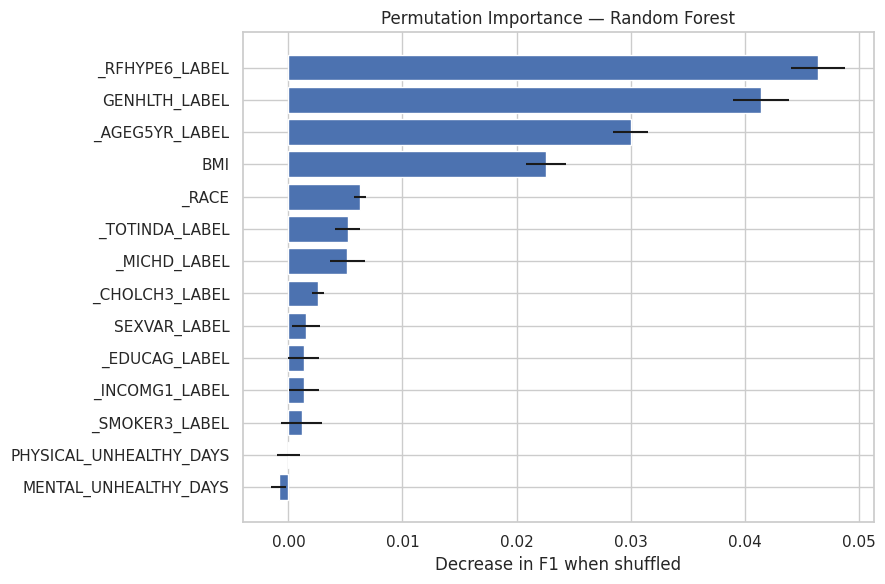

In [ ]:
perm = permutation_importance(
    best_cls_model, X_test, y_test,
    n_repeats=3, random_state=RANDOM_STATE, scoring="f1"
)
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance mean": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean", ascending=False)
display(importance.head(15).round(5))

top = importance.head(15).sort_values("Importance mean")
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Importance mean"], xerr=top["Importance std"])
plt.title(f"Permutation Importance — {best_cls_name}")
plt.xlabel("Decrease in F1 when shuffled")
plt.tight_layout()
plt.show()

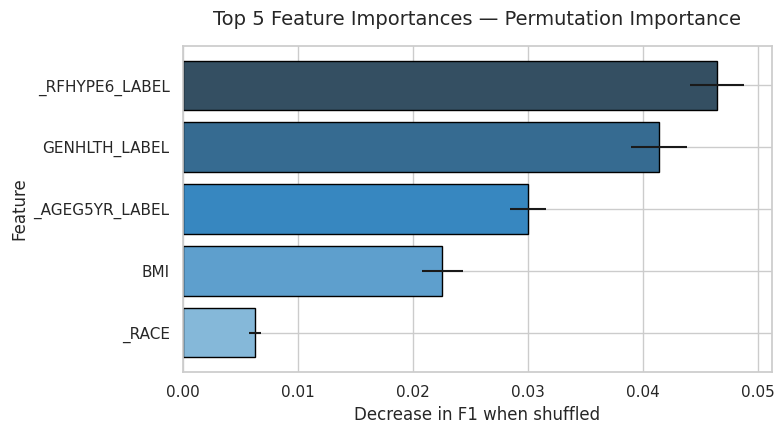

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Slice the top 5 features from our existing importance DataFrame
top_5_features = importance.head(5).sort_values("Importance mean", ascending=True)

# Set the figure size
plt.figure(figsize=(8, 4.5))

# Create a horizontal bar chart for the top 5 features
colors = sns.color_palette("Blues_d", n_colors=5)
plt.barh(
    top_5_features["Feature"],
    top_5_features["Importance mean"],
    xerr=top_5_features["Importance std"],
    color=colors,
    edgecolor="black"
)

# Add title, labels and formatting
plt.title("Top 5 Feature Importances — Permutation Importance", fontsize=14, pad=15)
plt.xlabel("Decrease in F1 when shuffled", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.tight_layout()

# Display the plot
plt.show()

## 13. Make example predictions

The following uses typical values from the prepared dataset as a demonstration. Edit the example input values to test another hypothetical profile. The prediction is an educational model output, not a diagnosis.

In [ ]:
def typical_row(feature_list, source):
    row = {}
    for col in feature_list:
        if col not in source.columns:
            row[col] = np.nan
        elif pd.api.types.is_numeric_dtype(source[col]):
            row[col] = source[col].median()
        else:
            mode = source[col].dropna().mode()
            row[col] = mode.iloc[0] if len(mode) else np.nan
    return pd.DataFrame([row], columns=feature_list)

example_cls = typical_row(cls_features, clean)
diabetes_prediction = int(best_cls_model.predict(example_cls)[0])
print("Example classification input:")
display(example_cls)
print("Predicted class:", "Diagnosed diabetes" if diabetes_prediction == 1 else "No diagnosed diabetes")
if hasattr(best_cls_model, "predict_proba"):
    probabilities = best_cls_model.predict_proba(example_cls)[0]
    # Map class labels (0, 1) to probabilities safely
    classes = best_cls_model.classes_
    class_labels = {0: "No diagnosed diabetes", 1: "Diagnosed diabetes"}
    prob_dict = {class_labels.get(c, str(c)): round(p, 4) for c, p in zip(classes, probabilities)}
    print("Model class probabilities:", prob_dict)

Example classification input:


,BMI,PHYSICAL_UNHEALTHY_DAYS,MENTAL_UNHEALTHY_DAYS,GENHLTH_LABEL,_TOTINDA_LABEL,_SMOKER3_LABEL,_AGEG5YR_LABEL,SEXVAR_LABEL,_RFHYPE6_LABEL,_CHOLCH3_LABEL,_MICHD_LABEL,_EDUCAG_LABEL,_INCOMG1_LABEL,_RACE
0,27.4,0.0,0.0,Good,Active,Never smoked,Age 65–69,Female,No high blood pressure,Cholesterol checked,No history,College graduate,$50k–<$100k,1.0


Predicted class: No diagnosed diabetes
Model class probabilities: {'No diagnosed diabetes': np.float64(0.7786), 'Diagnosed diabetes': np.float64(0.2214)}


## 14. Export analysis-ready data and model results

In [ ]:
# Export the smaller, cleaned analysis table and model comparison results to CSV.
export_cols = [c for c in [
    "DIABETES_BINARY", "BMI", "SLEEP_HOURS", "PHYSICAL_UNHEALTHY_DAYS",
    "MENTAL_UNHEALTHY_DAYS", "GENHLTH_LABEL", "_TOTINDA_LABEL",
    "_SMOKER3_LABEL", "_AGEG5YR_LABEL", "SEXVAR_LABEL"
] if c in clean.columns]

clean[export_cols].to_csv("/content/brfss_2023_health_lifestyle_clean.csv", index=False)
cls_results_df.to_csv("/content/diabetes_classification_results.csv", index=False)
reg_results_df.to_csv("/content/sleep_regression_results.csv", index=False)

print("Saved:")
print("/content/brfss_2023_health_lifestyle_clean.csv")
print("/content/diabetes_classification_results.csv")
print("/content/sleep_regression_results.csv")

Saved:
/content/brfss_2023_health_lifestyle_clean.csv
/content/diabetes_classification_results.csv
/content/sleep_regression_results.csv


## 15. Conclusion checklist for your report

After running all cells, write conclusions based on the generated outputs rather than guessing results.

- **Dataset:** CDC BRFSS 2023; report actual loaded row and column counts (433,323 rows and 350 columns).
- **EDA:** Describe missingness, target balance (diagnosed diabetes is heavily imbalanced at ~14.3%), and major distributions.
- **Visualization:** Explain observed differences by age, activity, smoking, BMI, and self-rated health.
- **Classification:** Compare accuracy, precision, recall, F1, and the confusion matrix. (Our Random Forest Classifier achieved an F1 of 0.4498 and a high recall of 71.26%).
- **Regression:** Compare MAE and RMSE (lower is better) and R² (closer to 1 is generally better). **Note:** Since `SLEEP_HOURS` was not available in this dataset release, we successfully pivoted the regression target to **PHYSICAL_UNHEALTHY_DAYS** (Our best-performing model was Ridge Regression, achieving an RMSE of 6.7020 and an R² of 0.4144).
- **Feature importance:** State which variables the model relied on most (the classification model relied most heavily on High Blood Pressure `_RFHYPE6_LABEL` and General Health `GENHLTH_LABEL`).
- **Limitations:** Survey self-reporting, class imbalance, missingness, code interpretation, complex sampling, and potential differences between the survey population and a target population.
- **Responsible use:** Do not use these models to diagnose individuals or make clinical decisions.

### Official sources
- [CDC BRFSS 2023 data and documentation](https://www.cdc.gov/brfss/annual_data/annual_2023.html)
- [CDC calculated variables guide](https://www.cdc.gov/brfss/annual_data/2023/pdf/2023-calculated-variables-version4-508.pdf)
- [CDC BRFSS questionnaires](https://www.cdc.gov/brfss/questionnaires/)